# NYC Congestion Pricing: What Changed on the Roads?

**AMS 561 team project · Stony Brook University · March–May 2025**

On January 5, 2025, New York City began charging most vehicles that enter Manhattan below 60th Street. This notebook combines MTA and NYC DOT data from March 2024 to May 2025 to see how road speeds, crossing volumes, and subway ridership changed around the launch.

All data is read from one Excel workbook, `AMS_561_Project.xlsx`, which isn't included in this repo. See the [README](README.md) for the sheets it needs.

## Setup
pandas for cleaning and aggregating, Matplotlib for charts, `re` for parsing station names, and Folium for the interactive map.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import re
import folium
from folium.plugins import TimestampedGeoJson
from datetime import datetime

## 1. Congestion-zone entries
Totals the vehicles entering the congestion zone each day by detection group (sheet `MTA_CRZV`) and plots each group over time.

*Commented out in this version. Remove the `#` marks to run it.*

In [ ]:
# dfcrz = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_CRZV") # Number of vehicles that enter through each detection group a day

# dfcrz['Toll Date'] = pd.to_datetime(dfcrz['Toll Date'])
# dfcrz['Detection Group'] = dfcrz['Detection Group'].astype(str)

# entries = dfcrz.groupby([dfcrz['Detection Group'], 
#                          dfcrz['Toll Date'].dt.date])[['CRZ Entries','Excluded Roadway Entries']].sum().reset_index()

# entries.columns = ['Detection Group', 'Toll Date', 'CRZ Entries', 'Excluded Roadway Entries']
# entries['Toll Date'] = pd.to_datetime(entries['Toll Date'])

# bt = entries['Detection Group'].unique()
# btnum = len(bt)

# fig, axes = plt.subplots(btnum, 1, figsize=(10, 4 * btnum), sharex=False)

# for i, bridge in enumerate(bt):
#     bt_data = entries[entries['Detection Group'] == bridge]
#     axes[i].plot(bt_data['Toll Date'], bt_data['CRZ Entries'], marker='o')
#     axes[i].set_title(f"CRZ Entries Over Time - Group {bridge}")
#     axes[i].set_xlabel("Toll Date")
#     axes[i].set_ylabel("Entries")
#     axes[i].tick_params(axis='x', rotation=45)
# plt.tight_layout()
# plt.show()

## 2. Bridge and tunnel crossings
Adds E-ZPass and tolls-by-mail vehicles for each toll plaza per day (sheet `MTA_BT`), translates plaza codes such as `TBX`, `QMT`, and `VNB` into bridge and tunnel names, and plots each crossing over time.

*Commented out in this version. Remove the `#` marks to run it.*

In [ ]:
# def switch(p):
#     if p == "TBX":
#         return "Robert F. Kennedy Bridge Bronx Plaza and Queens Plaza"
#     elif p == "TBM":
#         return "Robert F. Kennedy Bridge Manhattan Plaza "
#     elif p == "BWB":
#         return "Bronx-Whitestone Bridge"
#     elif p == "HHB":
#         return " Henry Hudson Bridge"
#     elif p == "MPB":
#         return "Marine Parkway-Gil Hodges Memorial Bridge"
#     elif p == "CBB":
#         return " Cross Bay Veterans Memorial Bridge"
#     elif p == "QMT":
#         return " Queens Midtown Tunnel "
#     elif p == "HCT":
#         return " Hugh L. Carey Tunnel"
#     elif p == "TNB":
#         return "Throgs Neck Bridge"
#     elif p == "VNB":
#         return "Verrazano-Narrows Bridge"
# df2 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_BT") # Number of entries through buses and tunnels for 2024 and 2025

# bt_Totals = {}

# for index, row in df2.iterrows():
#     btdate = row['Date']
#     plaza= row['Plaza ID']
#     btEntries = row['# Vehicles - E-ZPass'] + row['# Vehicles - VToll']

#     if btdate not in bt_Totals :
#         bt_Totals[btdate] = {}
#     if plaza in bt_Totals[btdate]:
#         bt_Totals[btdate][plaza] += btEntries
#     else:
#         bt_Totals[btdate][plaza] = btEntries  

# dfbt = pd.DataFrame(bt_Totals).T 
# dfbt.index = pd.to_datetime(dfbt.index)
# dfbt = dfbt.sort_index()

# pza = dfbt.columns
# pza_num = len(pza)

# fig, axes = plt.subplots(pza_num, 1, figsize=(12, 4 * pza_num), sharex=True)

# for i, plaza in enumerate(pza):
#     axes[i].plot(dfbt.index, dfbt[plaza], marker='o')
#     axes[i].set_title(f"Vehicle Entries Over Time at - {switch(plaza)}")
#     axes[i].set_ylabel("Entries")
#     axes[i].tick_params(axis='x', rotation=45)

# axes[-1].set_xlabel("Date")
# plt.tight_layout()
# plt.show()

## 3. Subway ridership in 2024
Plots daily systemwide subway rides for 2024 (sheet `MTA_Rides_2024`), the baseline before congestion pricing.

*Commented out in this version. Remove the `#` marks to run it.*

In [ ]:
# df3 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_Rides_2024") # Dataframe for 2024 subway rides

# preCRZ_Totals = {}

# for index, row in df3.iterrows():
#     predate = row['Date']
#     presubways= row['Subways']
#     preCRZ_Totals[predate] = {'Subways': presubways}
    
# df3 = pd.DataFrame(preCRZ_Totals).T 
# df3.index = pd.to_datetime(df3.index)
# df3 = df3.sort_index()

# plt.figure(figsize=(20,10))
# plt.ylim(0, 5000000)
# plt.xlim(pd.to_datetime("2024-01-01"), pd.to_datetime("2024-12-31"))
# plt.plot(df3.index, df3['Subways'], marker='o', label='Subways')
# plt.title(f"Subway Ridership 2024")
# plt.xlabel("Date (For the past year)")
# plt.ylabel("Rides (in millions)")
# plt.tick_params(axis='x', rotation=45)
# plt.show()

## 4. Subway ridership in 2025, by line
Station names include their lines in parentheses, e.g. `(2,3)`. A regular expression pulls those lines out, and the daily ridership of every station on the selected lines (2, 3, 6, 7, A, B, C, D, E, F, J, L, M, N, Q, R, W) is summed and plotted (sheet `MTA_Station_Rides_2025`).

*Commented out in this version. Remove the `#` marks to run it.*

In [ ]:
# df4 = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "MTA_Station_Rides_2025")
# ways = ['2','3','6','7','A','B','C','D','E','F','J','L','M','N','Q','R','W']
# postCRZ_subways = {}

# for index, row in df4.iterrows():
#     subdate = pd.to_datetime(row['Date']).date() 
#     rides = float(row['Estimated Average Ridership'])
#     station =str(row['Station Name'])
#     raw_lines = re.findall(r'\((.*?)\)', station)
#     lines = []
    
#     for group in raw_lines:
#         parts = group.split(',')
#         lines.extend([p.strip() for p in parts])
        
#     if any(x in ways for x in lines):
#         if subdate in postCRZ_subways:
#             postCRZ_subways[subdate] += rides
#         else:
#             postCRZ_subways[subdate] = rides
        
# dfsub = pd.DataFrame(list(postCRZ_subways.items()), columns=['Date', 'Avg Rides'])
# dfsub['Date'] = pd.to_datetime(dfsub['Date'])
# dfsub = dfsub.sort_values('Date')
# plt.figure(figsize=(12, 6))
# plt.plot(dfsub['Date'], dfsub['Avg Rides'], marker='o')
# plt.ylim(0,2000000)
# plt.title("Subway Ridership by Date")
# plt.xlabel("Date")
# plt.ylabel("Ridership (in millions)")
# plt.grid(True)
# plt.tight_layout()
# plt.xticks(rotation=45)
# plt.show()

## 5. Interactive traffic-speed map
NYC DOT reports speeds for each road segment, with the segment's shape stored as a string of `lat,lon` points (sheet `Traffic_Speeds`). This step:

- parses those points into line geometry, skipping rows that can't be parsed,
- averages the speed of each segment per day,
- colors each segment from red (slow) to green (fast), and
- builds a Folium map with a day-by-day time slider.

The map is saved as `nyc_speed_time_slider_map.html`. Open it in a browser.

In [ ]:
dfstreets = pd.read_excel("AMS_561_Project.xlsx", sheet_name = "Traffic_Speeds") 

dfstreets['DATA_AS_OF'] = pd.to_datetime(dfstreets['DATA_AS_OF'])
dfstreets['DATE'] = dfstreets['DATA_AS_OF'].dt.date
dfstreets['LINK_NAME'] = dfstreets['LINK_NAME'].astype(str)

def parse_link_points(link_str):
    try:
        points = link_str.strip().split()
        return [(float(lat), float(lon)) for lat, lon in (point.split(',') for point in points)]
    except:
        return None

dfstreets['geometry'] = dfstreets['LINK_POINTS'].apply(parse_link_points)
dfstreets = dfstreets.dropna(subset=['geometry'])

daily_avg = dfstreets.groupby(['LINK_NAME', 'DATE']).agg({'SPEED': 'mean','geometry': 'first'}).reset_index()

min_speed = daily_avg['SPEED'].min()
max_speed = daily_avg['SPEED'].max()
norm = colors.Normalize(vmin=min_speed, vmax=max_speed)
cmap = plt.colormaps.get_cmap('RdYlGn')

features = []
for date in sorted(daily_avg['DATE'].unique()):
    day_data = daily_avg[daily_avg['DATE'] == date]
    for _, row in day_data.iterrows():
        color = colors.to_hex(cmap(norm(row['SPEED'])))
        features.append({'type': 'Feature',
                         'geometry': {'type': 'LineString','coordinates': [(lon, lat) for lat, lon in row['geometry']]},
                         'properties': {'time': str(datetime.combine(date, datetime.min.time())),'style': {'color': color,'weight': 2
                },
                'popup': f"{row['LINK_NAME']} — {row['SPEED']:.2f} mph"
            }
        })
geojson = {
    'type': 'FeatureCollection',
    'features': features
}

# Create interactive map
m = folium.Map(location=[40.73, -73.98], zoom_start=12)
TimestampedGeoJson(
    geojson,
    period='P1D',
    add_last_point=False,
    auto_play=False,
    loop=False,
    max_speed=1,
    loop_button=True,
    date_options='YYYY-MM-DD',
    time_slider_drag_update=True
).add_to(m)

# Save output
m.save("nyc_speed_time_slider_map.html")

## 6. Speed trends by road segment
One chart per road segment, showing its average daily speed from March 2024 to May 2025.

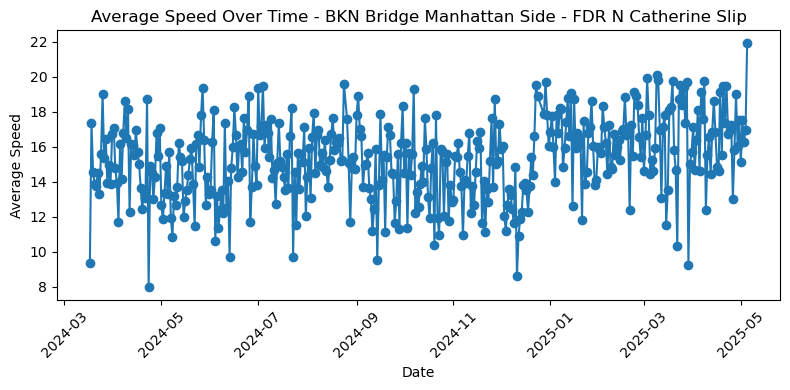

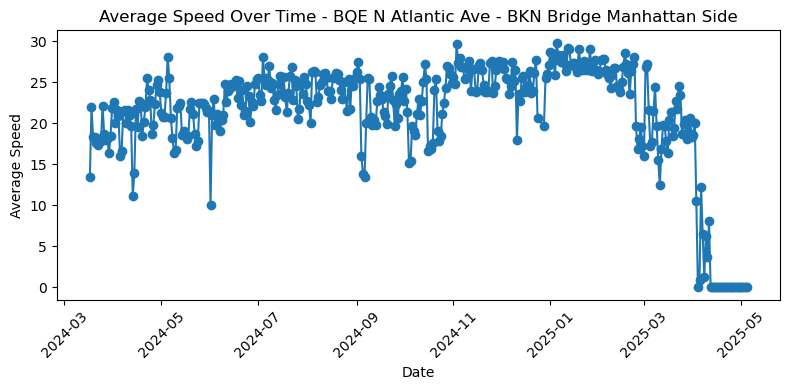

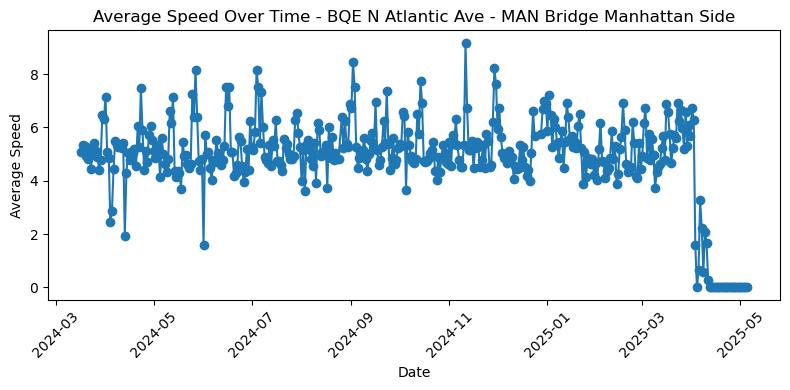

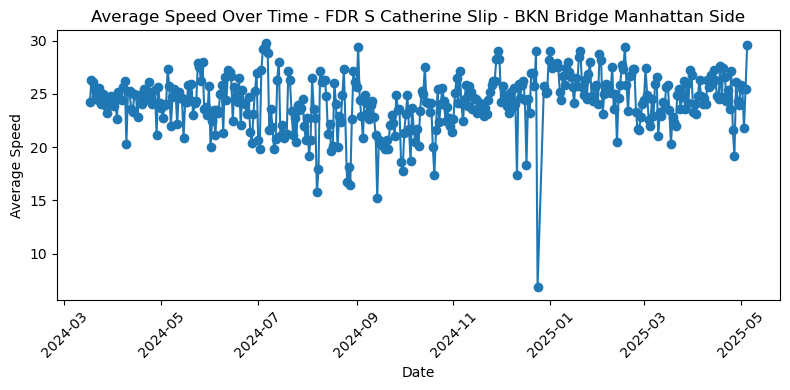

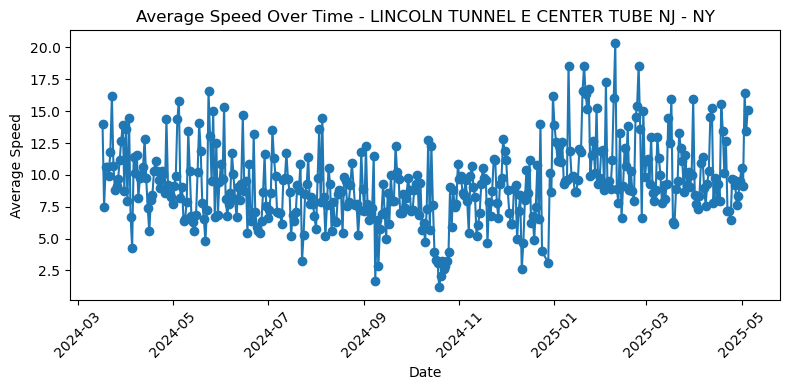

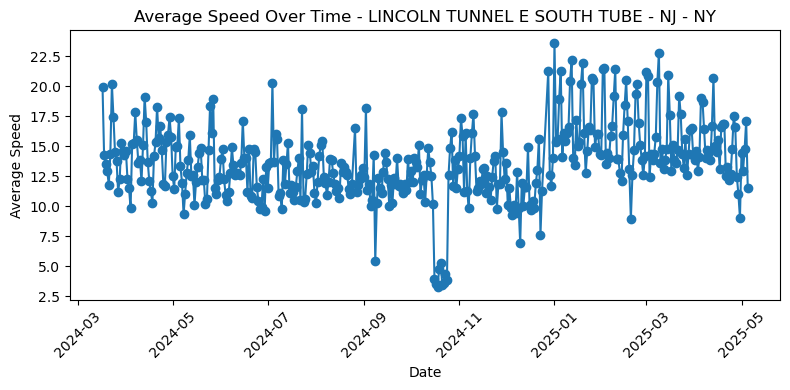

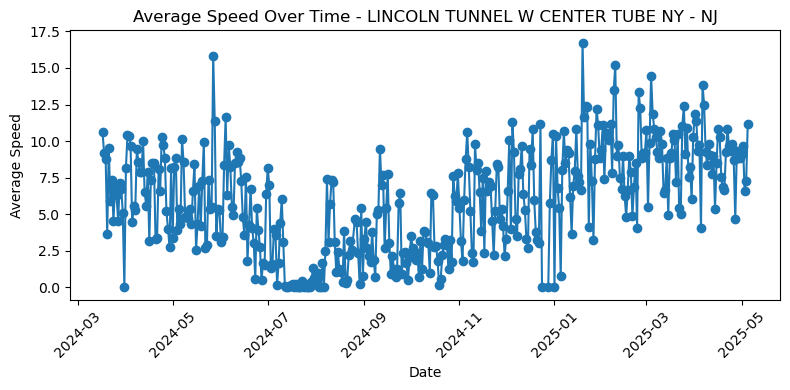

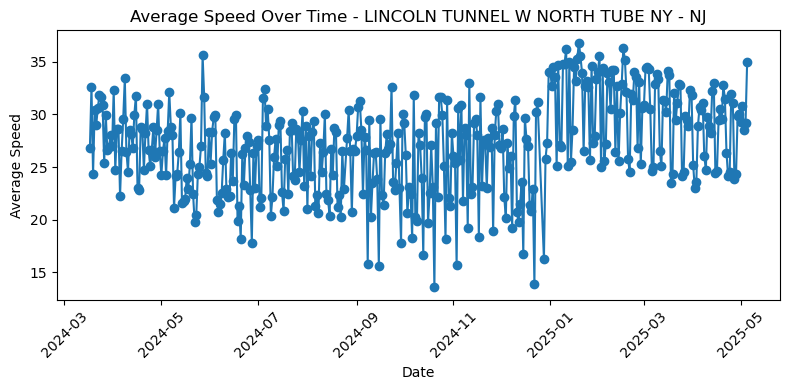

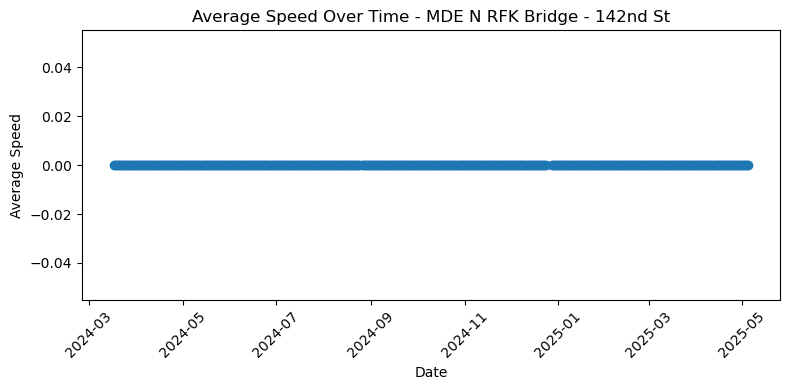

In [12]:
dfstreets['DATA_AS_OF'] = pd.to_datetime(dfstreets['DATA_AS_OF'])
dfstreets['LINK_NAME'] = dfstreets['LINK_NAME'].astype(str)
avg_speed = dfstreets.groupby([dfstreets['LINK_NAME'], dfstreets['DATA_AS_OF'].dt.date])['SPEED'].mean().reset_index()
avg_speed.columns = ['Street', 'Date', 'Average_Speed']
heatmap_data = avg_speed.pivot(index='Street', columns='Date', values='Average_Speed')

for street in avg_speed['Street'].unique():
    speed = avg_speed[avg_speed['Street'] == street]

    plt.figure(figsize=(8, 4))
    plt.plot(pd.to_datetime(speed['Date']), speed['Average_Speed'], marker='o')
    plt.title(f"Average Speed Over Time - {street}")
    plt.xlabel("Date")
    plt.ylabel("Average Speed")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

## What we found
- **Lincoln Tunnel speeds rose after pricing began.** The westbound north tube went from mostly mid-20s mph to the low 30s.
- **Not every drop was traffic.** We concluded a broken tunnel sensor caused the stretch with no readings in the Lincoln Tunnel west center tube (summer 2024). BQE segments falling to 0 mph in April 2025 and an MDE/RFK segment reading 0 the whole period also point to sensor problems rather than real stoppages.
- We presented our findings with policy recommendations for urban transportation planning.